# Blue Ridge 6LiF run October 2026 deposit SN01

We have the first data on nominal 300 nm thick deposits in enriched LiF on Silicon (etched, I believe). Blue Ridge had trouble with the powdered LiF and Woollam had to use a small interlayer to fit the data. This time they fit a constant void percentage so I will make my
total thickness using the formula

total thickness = (top layer thickness) + (fill fraction) * (interlayer thickness)

As usual we start with some tools.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from DepositData5 import DepositData

In [9]:
sn01 = DepositData.from_file('Run10_26_SN01.txt', '6LiF on Si')

Using t1
Using t2
Using grading
Using roughness


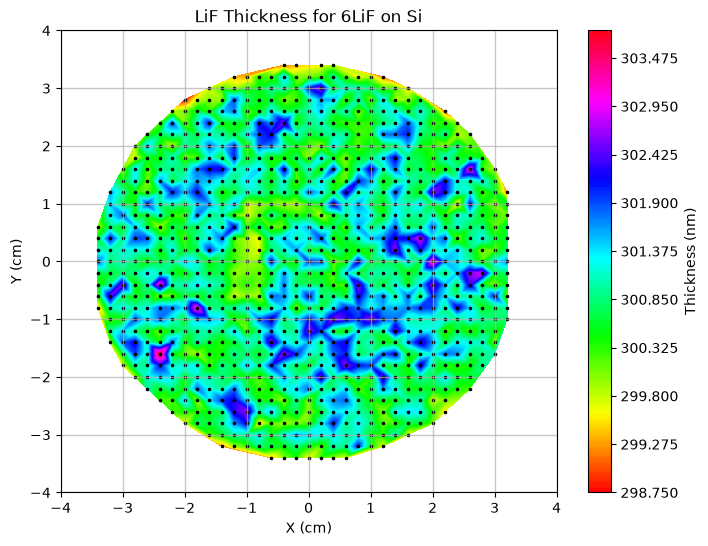

In [10]:
sn01.Ron_plot()

Well that is rather pretty! It is much better than either the top or interlayer. It is also not quite correct because it does not use the void fraction but simplly add the two layers. If we build a thickness using the void fraction (15.3%, so fill fraction = 84.7%)

In [11]:
zc01 = sn01.t1 + 0.847 * sn01.t2

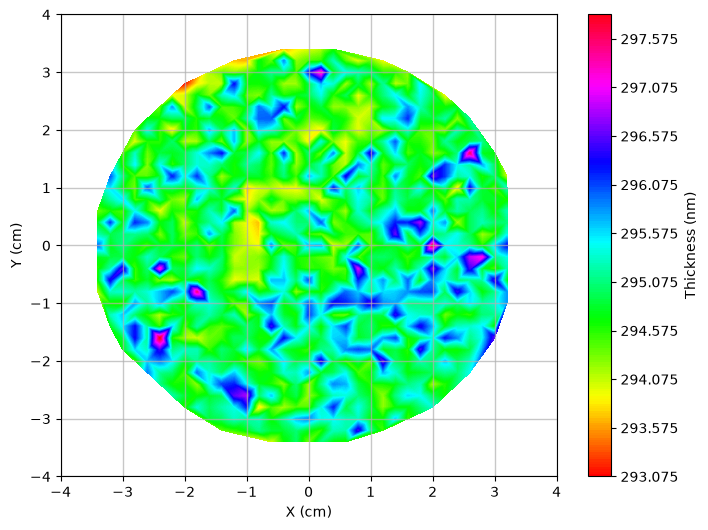

In [12]:
sn01.contour_plot(zc01)

Slightly lower (as we would expect) but still looks pretty flat. Let's try a 3-D plot.    

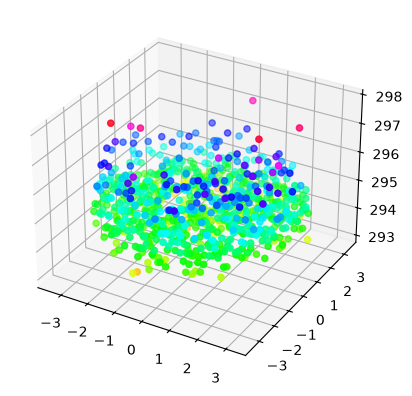

In [14]:
        fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
        surf = ax.scatter(sn01.xdata[sn01.mask], sn01.ydata[sn01.mask], 
                          zc01[sn01.mask], c= zc01[sn01.mask],
                          cmap='hsv')


Well, I don't see much there. It looks flat with noise above and below. that would be brilliant! Let's try a planar fit. First we have to replace the default zdata with our void corrected data.

In [16]:
sn01.zdata = zc01

In [17]:
# Scaled initial parameters
ipg = [ 5.96,  0.0, 0.0]

def planar_fit(p, a):
    return DepositData.fit_helper(p, a, 'angled_plane')

In [19]:
sn01f =sn01.fit_to(planar_fit, ipg)
print(sn01f)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 375.48082309009726
        x: [ 2.950e+02  2.134e+00  8.724e-02]
      nit: 26
      jac: [-7.248e-05  1.488e-04 -8.698e-04]
 hess_inv: [[ 5.330e-04  5.587e-05  4.697e-06]
            [ 5.587e-05  2.416e-02 -8.969e-05]
            [ 4.697e-06 -8.969e-05  1.884e-04]]
     nfev: 152
     njev: 38


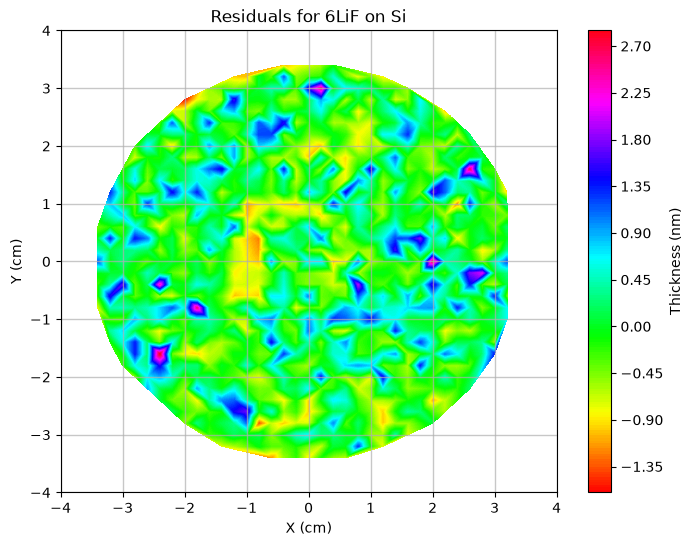

In [21]:
sn01.resid_plot()

Great! It looks exactly the same. To do more I need a machine that has a running version of Spyder.